# Task 1 — Exploratory Data Analysis (EDA)
## Palmer Penguins Dataset

**Objective:** Explore a public dataset, profile its data quality, handle missing values and duplicates, detect potential outliers, create statistical visualizations, and document findings supported by the observed data.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn.

**How to run:** In Google Colab, run **Runtime → Run all** from top to bottom. The dataset is downloaded from a public URL, so an internet connection is required.

**Important:** IQR flags potential outliers; it does not prove that a record is wrong. This notebook does not automatically remove outliers.

## Cell 1 — Import libraries

The libraries below are used for data handling, numerical calculations, plots, and display.

In [28]:
import os
import zipfile
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("default")
sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

Libraries imported successfully.
Output folder: /content/eda_outputs


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Cell 2 — Load and validate the public dataset

We use the Palmer Penguins dataset. The validation step checks that the expected columns exist before analysis continues.

In [29]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "allisonhorst/palmerpenguins/main/"
    "inst/extdata/penguins.csv"
)

EXPECTED_COLUMNS = [
    "species", "island", "bill_length_mm", "bill_depth_mm",
    "flipper_length_mm", "body_mass_g", "sex", "year"
]

try:
    df_original = pd.read_csv(DATA_URL)
except Exception as exc:
    raise RuntimeError(
        "Could not download the dataset. Check your internet connection "
        "and try running this cell again."
    ) from exc

missing_columns = [c for c in EXPECTED_COLUMNS if c not in df_original.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

df_original = df_original[EXPECTED_COLUMNS].copy()
df = df_original.copy()

print("Dataset loaded and validated successfully.")
print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset loaded and validated successfully.
Dataset shape (rows, columns): (344, 8)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Cell 3 — Summary profiling

This reports column names, data types, non-null counts, and descriptive statistics.

In [30]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

profile = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Missing Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
display(profile)
profile.to_csv(OUTPUT_DIR / "data_profile.csv", index=True)

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB

Statistical summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,344.0,NaN,NaN,NaN,2008.02907,0.818356,2007.0,2007.0,2008.0,2009.0,2009.0


,Data Type,Non-Missing Count,Missing Count,Missing Percentage
species,object,344,0,0.00
island,object,344,0,0.00
bill_length_mm,float64,342,2,0.58
bill_depth_mm,float64,342,2,0.58
flipper_length_mm,float64,342,2,0.58
body_mass_g,float64,342,2,0.58
sex,object,333,11,3.20
year,int64,344,0,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Cell 4 — Missing-value analysis

We record both counts and percentages before making cleaning decisions. The heatmap visualizes where values are missing.

,Missing Count,Missing Percentage
sex,11,3.20
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
bill_length_mm,2,0.58
body_mass_g,2,0.58
island,0,0.00
species,0,0.00
year,0,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


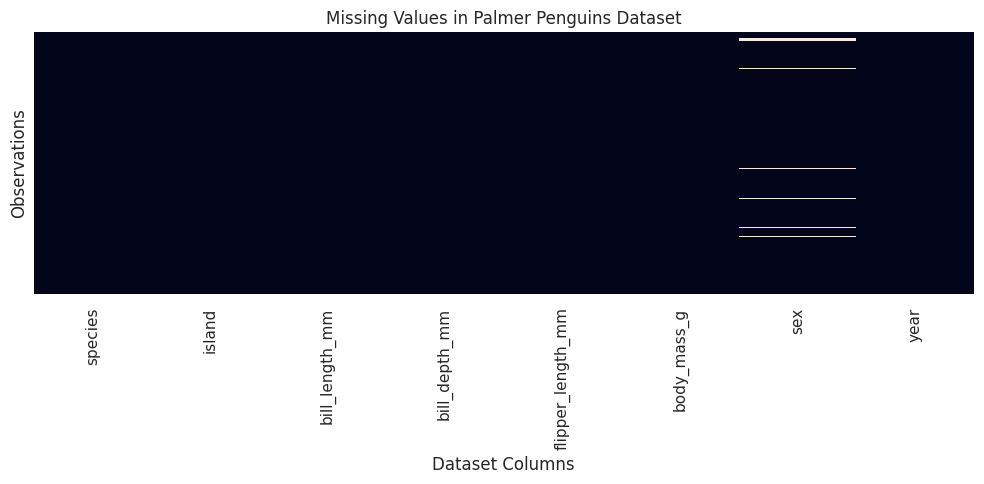

Observation: Missing values were found in:
- sex: 11 values (3.20%).
- bill_depth_mm: 2 values (0.58%).
- flipper_length_mm: 2 values (0.58%).
- bill_length_mm: 2 values (0.58%).
- body_mass_g: 2 values (0.58%).
Practical implication: inspect missingness by column before choosing imputation or row removal; avoid replacing meaningful measurements with zero.


In [31]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)
missing_summary.to_csv(OUTPUT_DIR / "missing_values_before_cleaning.csv")

plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing Values in Palmer Penguins Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Observations")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

columns_with_missing = missing_summary[missing_summary["Missing Count"] > 0]
if columns_with_missing.empty:
    print("Observation: No missing values were found in this dataset.")
else:
    print("Observation: Missing values were found in:")
    for col, row in columns_with_missing.iterrows():
        print(f"- {col}: {int(row['Missing Count'])} values ({row['Missing Percentage']:.2f}%).")
print(
    "Practical implication: inspect missingness by column before choosing "
    "imputation or row removal; avoid replacing meaningful measurements with zero."
)

## Cell 5 — Duplicate-row analysis

We measure exact duplicate rows first, then remove exact duplicates only. This is different from removing records merely because they contain missing values.

In [32]:
duplicate_count = int(df.duplicated().sum())
duplicate_percentage = (duplicate_count / len(df) * 100) if len(df) else 0

print("Exact duplicate rows:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

df = df.drop_duplicates().copy()

print("Original shape:", df_original.shape)
print("Shape after removing exact duplicates:", df.shape)
print("Remaining exact duplicate rows:", int(df.duplicated().sum()))

pd.DataFrame({
    "Measure": ["Original rows", "Exact duplicates removed", "Rows after duplicate removal"],
    "Value": [len(df_original), duplicate_count, len(df)]
}).to_csv(OUTPUT_DIR / "duplicate_report.csv", index=False)

Exact duplicate rows: 0
Duplicate percentage: 0.00%
Original shape: (344, 8)
Shape after removing exact duplicates: (344, 8)
Remaining exact duplicate rows: 0


## Cell 6 — Missing-value treatment and mathematical justification

For numerical measurements, the median is used because it is less sensitive to extreme values than the mean. For categorical columns, the most frequent category (mode) is used when available. We preserve the pre-cleaning missing-value report so the original data quality remains documented.

This is a simple EDA strategy, not a claim that imputed values are true measurements.

In [33]:
df_clean = df.copy()

measurement_cols = [
    "bill_length_mm", "bill_depth_mm",
    "flipper_length_mm", "body_mass_g"
]
categorical_cols = ["species", "island", "sex"]

imputation_log = []

for col in measurement_cols:
    missing_before = int(df_clean[col].isna().sum())
    if missing_before > 0:
        fill_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(fill_value)
        imputation_log.append({
            "Column": col,
            "Method": "Median",
            "Missing values filled": missing_before,
            "Fill value": fill_value
        })

for col in categorical_cols:
    missing_before = int(df_clean[col].isna().sum())
    if missing_before > 0:
        modes = df_clean[col].mode(dropna=True)
        if not modes.empty:
            fill_value = modes.iloc[0]
            df_clean[col] = df_clean[col].fillna(fill_value)
            imputation_log.append({
                "Column": col,
                "Method": "Mode",
                "Missing values filled": missing_before,
                "Fill value": fill_value
            })

# Year is numeric but represents observation year; if missing, median is used.
if df_clean["year"].isna().any():
    missing_before = int(df_clean["year"].isna().sum())
    fill_value = df_clean["year"].median()
    df_clean["year"] = df_clean["year"].fillna(fill_value)
    imputation_log.append({
        "Column": "year",
        "Method": "Median",
        "Missing values filled": missing_before,
        "Fill value": fill_value
    })

imputation_report = pd.DataFrame(
    imputation_log,
    columns=["Column", "Method", "Missing values filled", "Fill value"]
)
print("Imputation report:")
display(imputation_report if not imputation_report.empty else pd.DataFrame(
    {"Message": ["No missing values required imputation."]}
))

print("\nMissing values after treatment:")
display(df_clean.isna().sum().to_frame("Remaining Missing Values"))

imputation_report.to_csv(OUTPUT_DIR / "imputation_report.csv", index=False)

if df_clean.isna().any().any():
    print("Warning: some missing values remain. Review the report before submission.")
else:
    print("All missing values in the selected dataset columns have been handled.")

Imputation report:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Column,Method,Missing values filled,Fill value
0,bill_length_mm,Median,2,44.45
1,bill_depth_mm,Median,2,17.3
2,flipper_length_mm,Median,2,197.0
3,body_mass_g,Median,2,4050.0
4,sex,Mode,11,male



Missing values after treatment:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Remaining Missing Values
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0
year,0


All missing values in the selected dataset columns have been handled.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Cell 7 — Outlier detection with the IQR rule

For each physical measurement, compute Q1, Q3, IQR, and the 1.5 × IQR bounds. These are potential outliers, not automatic data errors. We keep them unless there is evidence that a value is invalid.

In [34]:
outlier_rows = []

for col in measurement_cols:
    series = df_clean[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())

    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outlier Count": count,
        "Potential Outlier Percentage": count / len(series) * 100 if len(series) else 0
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))
outlier_summary.to_csv(OUTPUT_DIR / "outlier_summary.csv", index=False)

print(
    "Interpretation: IQR flags values outside the calculated bounds. "
    "Because biological measurements can vary naturally, these records are "
    "retained unless independent evidence shows they are data errors."
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outlier Count,Potential Outlier Percentage
0,bill_length_mm,39.28,48.5,9.23,25.44,62.34,0,0.0
1,bill_depth_mm,15.60,18.7,3.10,10.95,23.35,0,0.0
2,flipper_length_mm,190.00,213.0,23.00,155.50,247.50,0,0.0
3,body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,0,0.0


Interpretation: IQR flags values outside the calculated bounds. Because biological measurements can vary naturally, these records are retained unless independent evidence shows they are data errors.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Cell 8 — Feature distributions with evidence-based observations

Each histogram is saved at 300 DPI. The printed observation includes the observed median, skewness, and range for that feature.

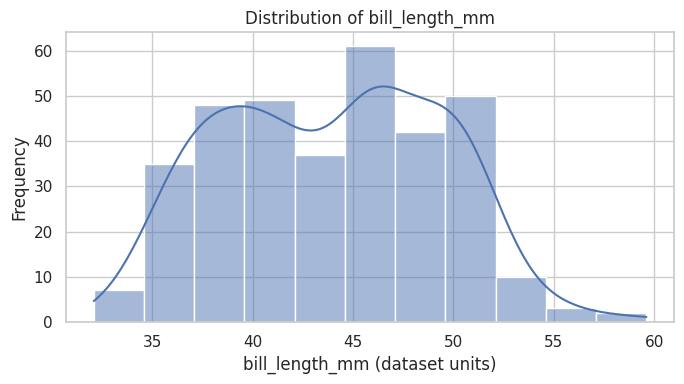

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Observation — bill_length_mm: median=44.45, range=32.10 to 59.60, skewness=0.05 (not strongly skewed by the ±0.5 rule).
Practical implication: use the displayed spread and skewness when summarizing typical values; the median may be more representative than the mean when the distribution is skewed.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


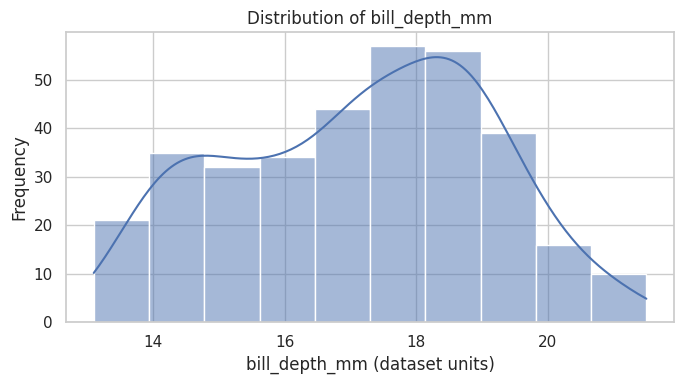

Observation — bill_depth_mm: median=17.30, range=13.10 to 21.50, skewness=-0.15 (not strongly skewed by the ±0.5 rule).
Practical implication: use the displayed spread and skewness when summarizing typical values; the median may be more representative than the mean when the distribution is skewed.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


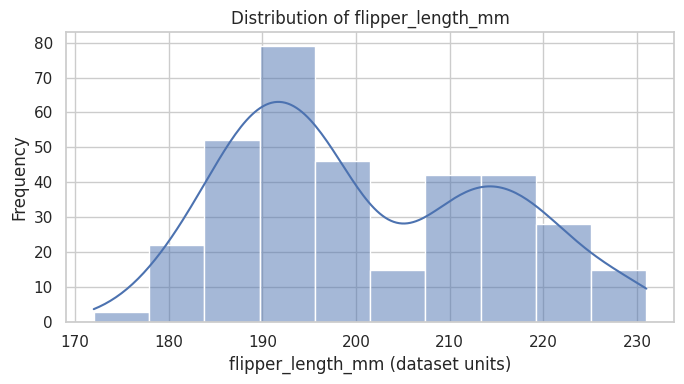

Observation — flipper_length_mm: median=197.00, range=172.00 to 231.00, skewness=0.35 (not strongly skewed by the ±0.5 rule).
Practical implication: use the displayed spread and skewness when summarizing typical values; the median may be more representative than the mean when the distribution is skewed.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


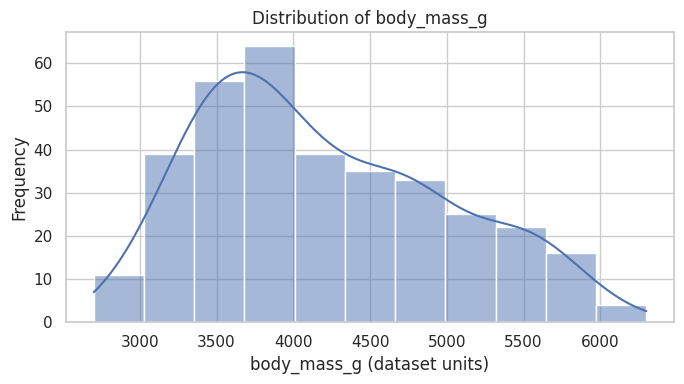

Observation — body_mass_g: median=4050.00, range=2700.00 to 6300.00, skewness=0.47 (not strongly skewed by the ±0.5 rule).
Practical implication: use the displayed spread and skewness when summarizing typical values; the median may be more representative than the mean when the distribution is skewed.



In [35]:
distribution_rows = []

for col in measurement_cols:
    series = df_clean[col].dropna()
    skewness = series.skew()
    median = series.median()
    minimum = series.min()
    maximum = series.max()

    plt.figure(figsize=(7, 4))
    sns.histplot(data=df_clean, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(f"{col} (dataset units)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"02_distribution_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

    shape_note = (
        "right-skewed" if skewness > 0.5 else
        "left-skewed" if skewness < -0.5 else
        "not strongly skewed by the ±0.5 rule"
    )
    print(
        f"Observation — {col}: median={median:.2f}, range={minimum:.2f} to "
        f"{maximum:.2f}, skewness={skewness:.2f} ({shape_note})."
    )
    print(
        "Practical implication: use the displayed spread and skewness when "
        "summarizing typical values; the median may be more representative "
        "than the mean when the distribution is skewed.\n"
    )

    distribution_rows.append({
        "Feature": col, "Median": median, "Minimum": minimum,
        "Maximum": maximum, "Skewness": skewness, "Distribution note": shape_note
    })

pd.DataFrame(distribution_rows).to_csv(
    OUTPUT_DIR / "distribution_summary.csv", index=False
)

## Cell 9 — Boxplots and outlier observations

Boxplots visualize medians, interquartile ranges, and points beyond the whiskers. The text below each plot reports the IQR-based potential outlier count from the previous calculation.

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


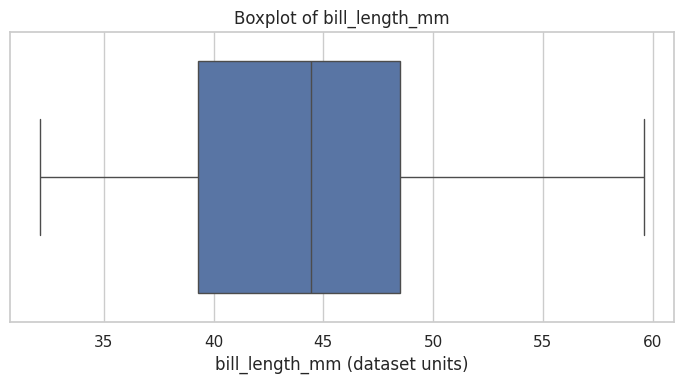

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


Observation — bill_length_mm: 0 potential IQR outlier(s) (0.00%).
Practical implication: investigate unusual values against source documentation before considering removal; unusual does not necessarily mean incorrect.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


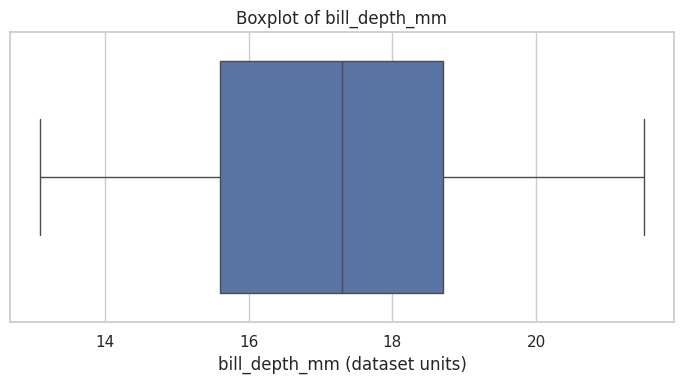

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


Observation — bill_depth_mm: 0 potential IQR outlier(s) (0.00%).
Practical implication: investigate unusual values against source documentation before considering removal; unusual does not necessarily mean incorrect.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


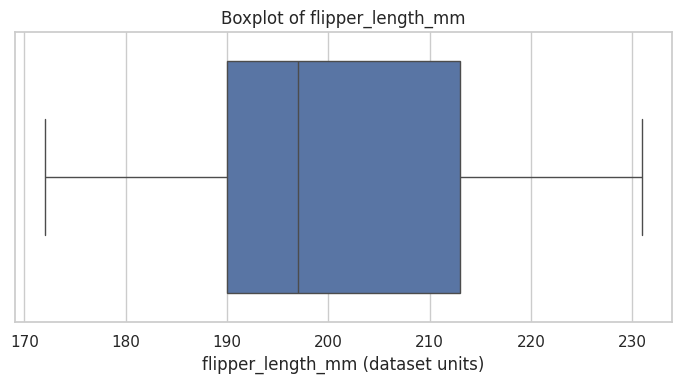

Observation — flipper_length_mm: 0 potential IQR outlier(s) (0.00%).
Practical implication: investigate unusual values against source documentation before considering removal; unusual does not necessarily mean incorrect.



/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


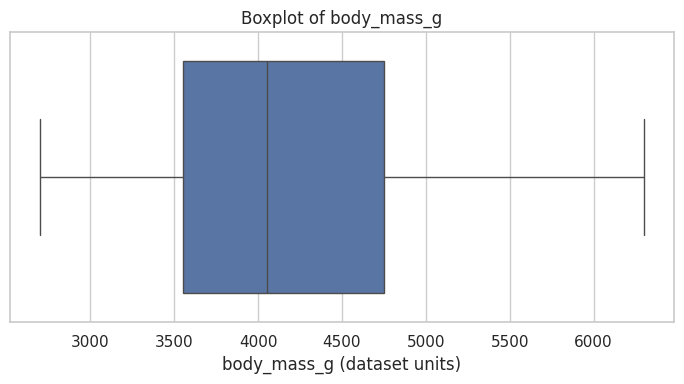

Observation — body_mass_g: 0 potential IQR outlier(s) (0.00%).
Practical implication: investigate unusual values against source documentation before considering removal; unusual does not necessarily mean incorrect.



In [24]:
outlier_lookup = outlier_summary.set_index("Feature")

for col in measurement_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_clean, x=col)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(f"{col} (dataset units)")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"03_boxplot_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

    row = outlier_lookup.loc[col]
    print(
        f"Observation — {col}: {int(row['Potential Outlier Count'])} "
        f"potential IQR outlier(s) ({row['Potential Outlier Percentage']:.2f}%)."
    )
    print(
        "Practical implication: investigate unusual values against source "
        "documentation before considering removal; unusual does not necessarily mean incorrect.\n"
    )

## Cell 10 — Correlation heatmap

This heatmap uses the four physical measurement columns. Correlation describes linear association and does not establish cause and effect.

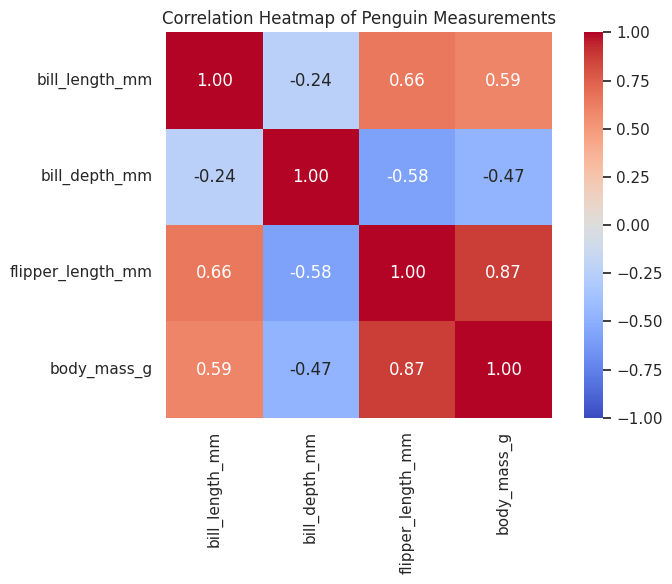

Observation: strongest positive pair is flipper_length_mm and body_mass_g (r=0.87).
Observation: strongest negative pair is bill_depth_mm and flipper_length_mm (r=-0.58).
Practical implication: strongly correlated measurements may provide overlapping information. Correlation does not prove that one measurement causes another.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
corr = df_clean[measurement_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Correlation Heatmap of Penguin Measurements")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

pairs = []
for i, col1 in enumerate(measurement_cols):
    for col2 in measurement_cols[i + 1:]:
        pairs.append((col1, col2, corr.loc[col1, col2]))

strongest_positive = max(pairs, key=lambda x: x[2])
strongest_negative = min(pairs, key=lambda x: x[2])

print(
    f"Observation: strongest positive pair is {strongest_positive[0]} and "
    f"{strongest_positive[1]} (r={strongest_positive[2]:.2f})."
)
print(
    f"Observation: strongest negative pair is {strongest_negative[0]} and "
    f"{strongest_negative[1]} (r={strongest_negative[2]:.2f})."
)
print(
    "Practical implication: strongly correlated measurements may provide "
    "overlapping information. Correlation does not prove that one measurement causes another."
)
corr.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

## Cell 11 — Pairwise scatter plots by species

The pairplot compares relationships between the four physical measurements. Species is used as a hue so possible group patterns are visible.

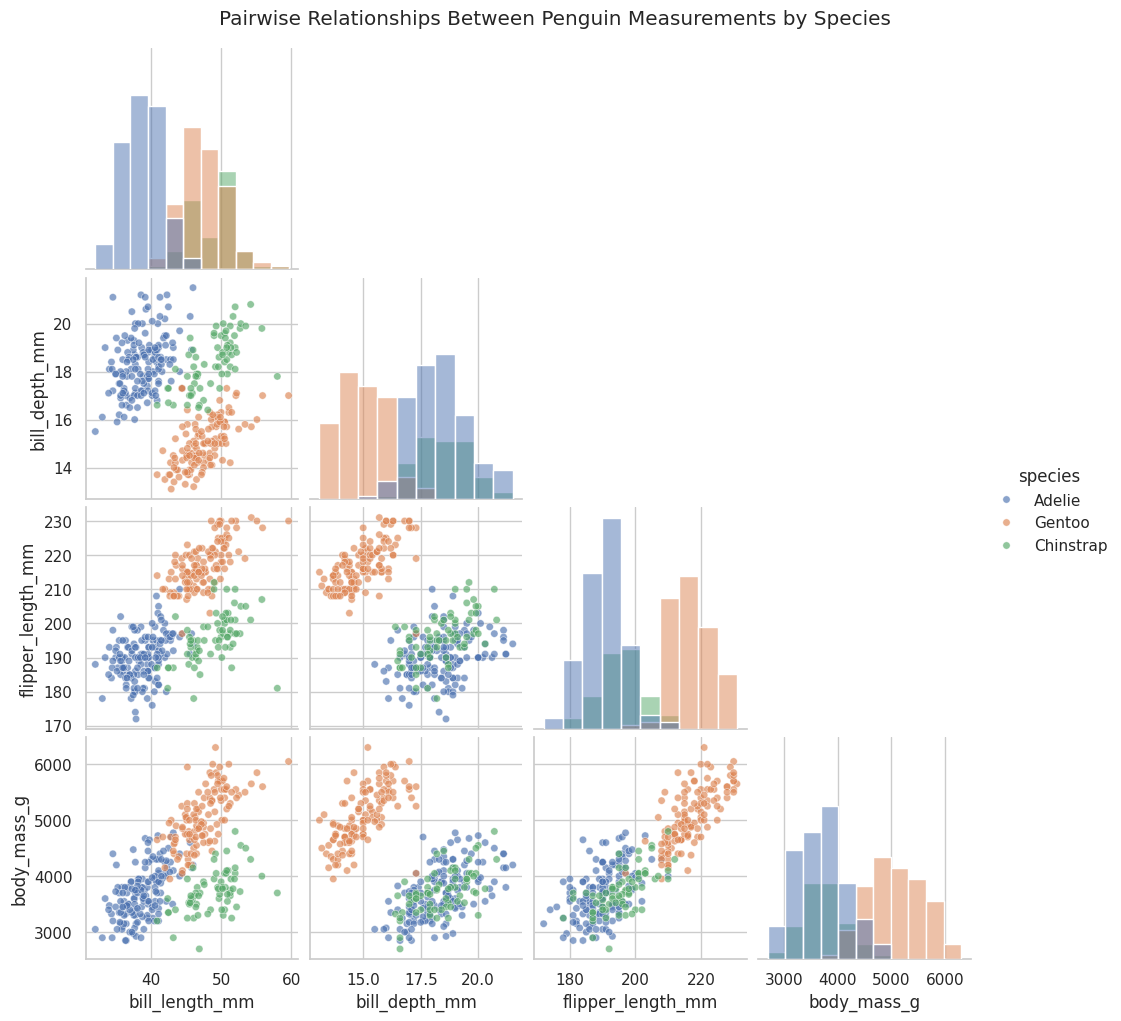

Species-wise measurement means:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.83,18.34,190.00,3702.96
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.48,15.00,217.02,5067.74


Observation: use the scatter panels and species-wise mean table together to identify which measurements appear to differ by species. Any apparent separation is descriptive and should be verified with further analysis.


In [26]:
pairplot = sns.pairplot(
    df_clean,
    vars=measurement_cols,
    hue="species",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.65, "s": 28}
)
pairplot.fig.suptitle(
    "Pairwise Relationships Between Penguin Measurements by Species",
    y=1.02
)
pairplot.savefig(
    OUTPUT_DIR / "05_pairwise_scatter_plots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Species-wise measurement means:")
species_means = df_clean.groupby("species", observed=True)[measurement_cols].mean().round(2)
display(species_means)
species_means.to_csv(OUTPUT_DIR / "species_measurement_means.csv")

print(
    "Observation: use the scatter panels and species-wise mean table together "
    "to identify which measurements appear to differ by species. Any apparent "
    "separation is descriptive and should be verified with further analysis."
)

## Cell 12 — Final data-quality check and export cleaned data

The original data-quality reports are retained. The cleaned dataset and key summaries are exported for review.

In [27]:
final_missing = int(df_clean.isna().sum().sum())
final_duplicates = int(df_clean.duplicated().sum())

print("Original shape:", df_original.shape)
print("Shape after duplicate removal and imputation:", df_clean.shape)
print("Remaining missing values:", final_missing)
print("Remaining exact duplicate rows:", final_duplicates)

df_clean.to_csv(OUTPUT_DIR / "penguins_cleaned.csv", index=False)

assert final_missing == 0, "Missing values remain; review the imputation step."
assert final_duplicates == 0, "Duplicate rows remain; review duplicate handling."

print("Final data-quality checks passed.")

Original shape: (344, 8)
Shape after duplicate removal and imputation: (344, 8)
Remaining missing values: 0
Remaining exact duplicate rows: 0
Final data-quality checks passed.
